# Basic TIS Setup with Toy Systems

This notebook demonstrates how to set up and run a basic TIS (Transition Interface Sampling) simulation using ops-setup with a toy potential.

No AIMMD learning is involved - this is pure Transition Interface Sampling.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import openpathsampling as paths
from pathlib import Path

# Import from ops-setup
from ops_setup.systems.examples.toy_systems import ToyTISSetup, potential_1

## 1. Create the TIS Setup

We'll use potential_1, which is a 2D system with two minima, and automatically generated interfaces.

In [2]:
# Setup TIS for toy potential 1
tis_setup = ToyTISSetup(
    potential_name='wolfe-quapp',
    potential_kwargs={'n_harmonics': 0, 'rotation_degrees': 0, 'scale': 2},
    integrator_params={
        'dt': 0.05,
        'temperature': 1,
        'gamma': 2.5
    },
    interface_values_forward=[-0.8, -0.6, -0.4, -0.2],  # 4 interfaces for TIS
    interface_values_backward=[0.8, 0.6, 0.4, 0.2]  # 4 interfaces for TIS
)

print(f"System: {tis_setup.system_name}")
print(f"MD Engine: {tis_setup.md_engine.name}")
print(f"States: {tis_setup.states}")
print(f"Interfaces Forward: {tis_setup.interface_values_forward}")
print(f"Interfaces Backward: {tis_setup.interface_values_backward}")

Setting up Langevin BAOAB integrator for toy system...
123
pot dimensions without oscillators: 2
harmonic oscillators omegas:
array([0., 0.])
Setting up Langevin BAOAB integrator for toy system...
Setting up toy engine for wolfe-quapp...
Creating snapshot template for toy system...
Defining states for wolfe-quapp...
System: wolfe-quapp
MD Engine: [ToyEngine]
States: (<openpathsampling.volume.CVDefinedVolume object at 0x10f479910>, <openpathsampling.volume.CVDefinedVolume object at 0x14ec73150>)
Interfaces Forward: [-0.8, -0.6, -0.4, -0.2]
Interfaces Backward: [0.8, 0.6, 0.4, 0.2]


## 2. Visualize the Potential Energy Surface and Interfaces

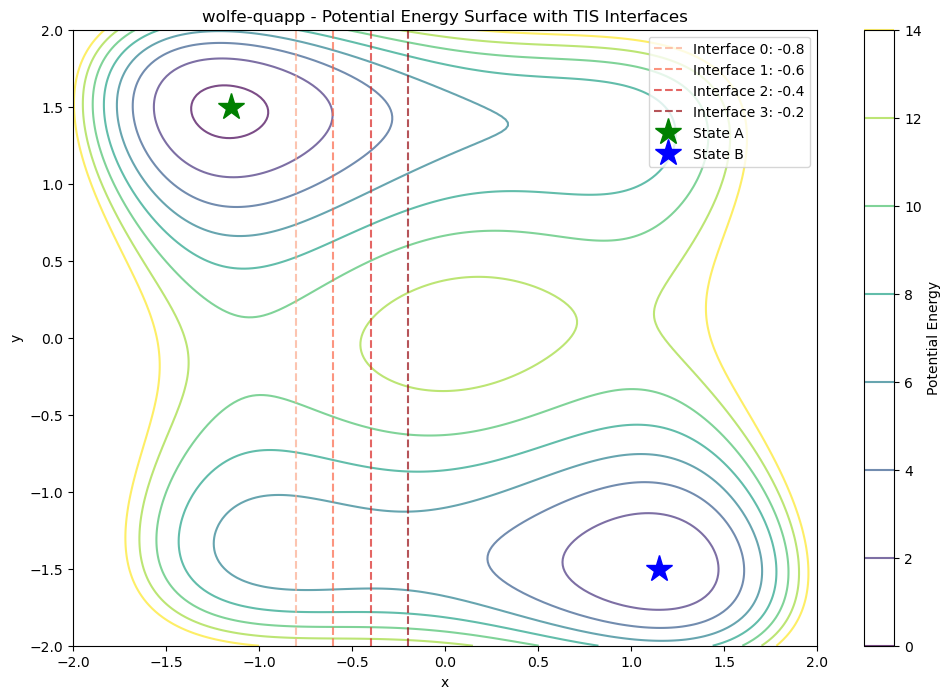

State A at: [-1.15  1.5 ]
State B at: [ 1.15 -1.5 ]


In [3]:
# Get the PES object
pes = tis_setup.pes

# Plot the 2D potential
x = np.linspace(pes.extent[0], pes.extent[1], 200)
y = np.linspace(pes.extent[2], pes.extent[3], 200)
X, Y, U = pes.plot_2d_pes(x, y)

# Get the CV for interfaces (x-coordinate for 2D systems)
cv = tis_setup.get_cv_for_interfaces()

plt.figure(figsize=(12, 8))
contours = plt.contour(X, Y, U, levels=pes.levels, cmap='viridis', alpha=0.7)
plt.colorbar(contours, label='Potential Energy')

# Draw interface lines (vertical lines for x-coordinate CV)
y_extent = [pes.extent[2], pes.extent[3]]
colors_interfaces = plt.cm.Reds(np.linspace(0.3, 0.9, len(tis_setup.interface_values_forward)))

for i, interface_val in enumerate(tis_setup.interface_values_forward):
    plt.axvline(interface_val, color=colors_interfaces[i], linestyle='--', 
                alpha=0.7, label=f'Interface {i}: {interface_val:.1f}')

# Mark states
plt.plot(pes.state_A[0], pes.state_A[1], 'g*', markersize=20, label='State A')
plt.plot(pes.state_B[0], pes.state_B[1], 'b*', markersize=20, label='State B')

plt.xlabel('x')
plt.ylabel('y')
plt.title(f'{tis_setup.system_name} - Potential Energy Surface with TIS Interfaces')
plt.legend(loc='upper right')
plt.show()

print(f"State A at: {pes.state_A}")
print(f"State B at: {pes.state_B}")

## 3. Create Initial Trajectories

For TIS, we need initial trajectories that cross each interface.

In [4]:
# Set engine for path movers
paths.PathMover.engine = tis_setup.md_engine

# Create initial trajectories for each interface ensemble
print("Creating initial trajectories for each interface...")

# For now, create a single initial trajectory
# In practice, you might use MD simulations to create more diverse starting conditions
init_traj = paths.Trajectory(pes.simple_initial_path(200, tis_setup.md_engine))

print(f"Initial trajectory length: {len(init_traj)} snapshots")
print(f"First frame coordinates: {init_traj[0].coordinates}")
print(f"Last frame coordinates: {init_traj[-1].coordinates}")

Creating initial trajectories for each interface...
Initial trajectory length: 200 snapshots
First frame coordinates: [[-1.15  1.5 ]]
Last frame coordinates: [[ 1.1385 -1.485 ]]


## 4. Create TIS Network

In [5]:
# Create TIS network
def xval(snapshot):
    return snapshot.xyz[0][0]

cvX = paths.CoordinateFunctionCV(name="cvX", f=xval).with_diskcache()

interface_val = tis_setup.interface_values_forward[0]

interface_volume= tis_setup.create_interface_set(cvX, interface_val, direction="forward")

network = tis_setup.create_tis_network(interface_volumes=interface_volume,direction="forward")
print(f"Network type: {type(network).__name__}")


Network type: MISTISNetwork


## 5. Create Move Scheme

In [6]:
# Create TIS move scheme
selector = tis_setup._create_selector("gaussian", collectivevariable=cvX, width=0.1, origin_shift=interface_val)

move_scheme = tis_setup.create_move_scheme(network, scheme_type="TwoWay", selector=selector)

print(f"Move scheme: {move_scheme}")
print(f"Movers: {len(move_scheme.movers)} movers")

for mover in move_scheme.movers:
    print(f"  {mover}")

Move scheme: <openpathsampling.high_level.move_scheme.MoveScheme object at 0x1588e8d10>
Movers: 1 movers
  TwoWayShooting


## 6. Initialize Storage

In [7]:
# Create storage for the simulation
storage_file = "toy_tis_example.nc"
storage = paths.Storage(storage_file, "w", template=tis_setup.template)

# Save the engine, network, and move scheme
storage.save(tis_setup.md_engine)
storage.save(tis_setup.template)
# storage.save(network)

print(f"Storage created: {storage_file}")

Storage created: toy_tis_example.nc


## 7. Create Initial Conditions and Run TIS

In [8]:
# Create initial conditions from trajectory
initial_conditions = move_scheme.initial_conditions_from_trajectories(init_traj)

# Sanity check
initial_conditions.sanity_check()
print("Initial conditions sanity check passed!")

# Create sampler
sampler = paths.PathSampling(storage, move_scheme, initial_conditions)

# Run for a few steps
n_steps = 50
print(f"\nRunning TIS for {n_steps} MC steps...")
sampler.run(n_steps)

print(f"\nTIS simulation complete!")
print(f"Total steps: {len(storage.steps)}")

Working on Monte Carlo cycle number 50
Running for 2 seconds -  0.05 seconds per step
Estimated time remaining: 0 seconds
DONE! Completed 50 Monte Carlo cycles.

TIS simulation complete!
Total steps: 51


Number of trajectories: 51

Trajectory lengths:
  Trajectory 0: 175 snapshots
  Trajectory 1: 22 snapshots
  Trajectory 2: 14 snapshots
  Trajectory 3: 14 snapshots
  Trajectory 4: 12 snapshots
  Trajectory 5: 17 snapshots
  Trajectory 6: 10 snapshots
  Trajectory 7: 9 snapshots
  Trajectory 8: 11 snapshots
  Trajectory 9: 12 snapshots
  Trajectory 10: 29 snapshots


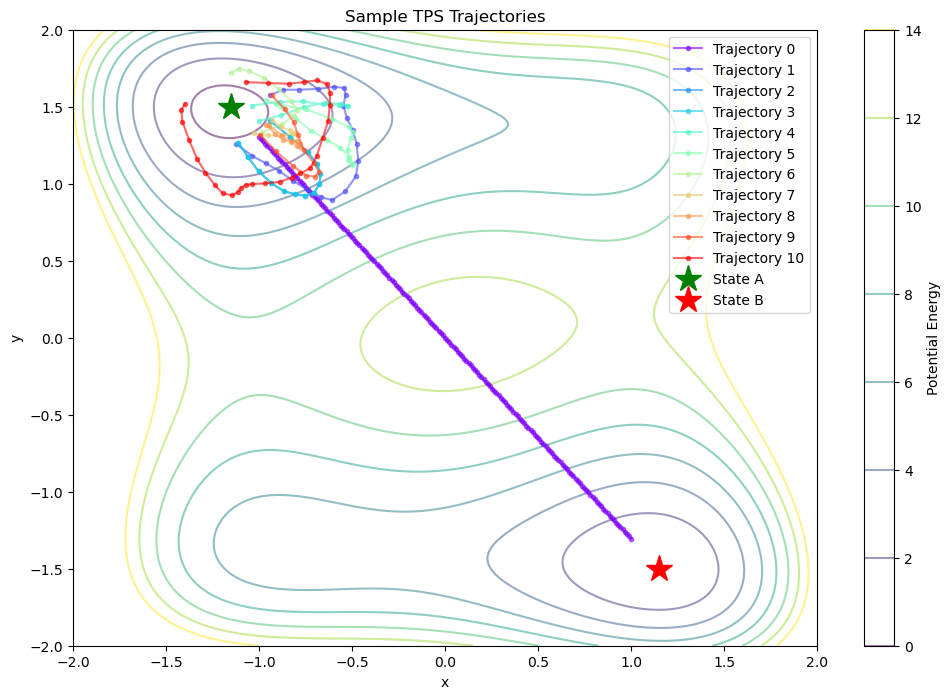


Trajectory plot complete!


In [9]:
# Extract trajectories
trajectories = [step.active[0].trajectory for step in storage.steps[:]]

print(f"Number of trajectories: {len(trajectories)}")
print(f"\nTrajectory lengths:")
for i, traj in enumerate(trajectories[::5]):
    print(f"  Trajectory {i}: {len(traj)} snapshots")
## 8. Plot Sample Trajectories
# Plot trajectories on the PES
plt.figure(figsize=(12, 8))

# Plot PES
contours = plt.contour(X, Y, U, levels=pes.levels, cmap='viridis', alpha=0.5)
plt.colorbar(contours, label='Potential Energy')

# Plot trajectories
colors = plt.cm.rainbow(np.linspace(0, 1, len(trajectories[::5])))
for i, traj in enumerate(trajectories[::5]):
    coords = np.array([snapshot.xyz[0][:2] for snapshot in traj])
    plt.plot(coords[:, 0], coords[:, 1], 'o-', alpha=0.6, color=colors[i], 
             label=f'Trajectory {i}', markersize=3)

# Mark states
if len(pes.state_A) == 2 and len(pes.state_B) == 2:
    plt.plot(pes.state_A[0], pes.state_A[1], 'g*', markersize=20, label='State A')
    plt.plot(pes.state_B[0], pes.state_B[1], 'r*', markersize=20, label='State B')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Sample TPS Trajectories')
plt.legend()
plt.show()

print("\nTrajectory plot complete!")

In [10]:
# Close storage
storage.close()
print(f"Storage closed: {storage_file}")

Storage closed: toy_tis_example.nc
